# Forecast Validation

## Research question
Can past-only calibration improve uncertainty without evaluation-label leakage?

## Data
Source: Bundesnetzagentur | SMARD.de. Observed period: January 2023-18 November 2026; 63,843 native price intervals and 136,128 quarter-hours per core load/wind/solar series. Physical quantities are German net grid/load generation; prices cover DE-LU. Actuals and forecasts remain separate; no missing physical value is replaced by zero.

## Methodology and equations
Each month uses prior 90-day out-of-sample scores s=max(q10-y,y-q90,0) before D-1 11:00 Berlin. Widen intervals by the finite-sample 80th percentile; evaluate coverage, width, pinball/MAE, Brier/AP and seven-day block confidence intervals.

In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import Image, display
root = Path.cwd() if Path('reports').exists() else Path.cwd().parent
os.chdir(root)


In [2]:
from power_risk.backtesting.validation import summarize
f=pd.read_parquet('reports/price_risk_forecasts_enhanced.parquet')
display(summarize(f))
display(pd.read_csv('reports/calibration_results.csv'))
display(pd.read_csv('reports/calibration_windows.csv').head())
display(pd.read_csv('reports/price_only_vs_fundamental.csv')[['model','feature_group','status']])

,model,observations,coverage_80,mean_width,pinball_q10,pinball_q50,pinball_q90,brier_p_negative,average_precision_p_negative,brier_p_spike,average_precision_p_spike
0,gradient_boosting / calibrated,16488,0.782084,92.892532,7.873507,15.753156,7.378964,0.045587,0.438057,0.040590,0.550371
1,gradient_boosting / original,16488,0.686014,76.257686,7.756658,15.753156,8.092611,0.041983,0.501753,0.048092,0.450669
2,linear_quantile / calibrated,16488,0.787482,135.692457,11.290754,17.229593,10.002341,0.055313,0.258479,0.048079,0.438930
3,linear_quantile / original,16488,0.738234,123.488101,11.102363,17.229593,10.331234,0.053118,0.211713,0.060002,0.273180
4,seasonal_history / calibrated,16488,0.801795,126.607565,10.490377,19.288342,10.841114,0.055313,0.258479,0.048079,0.438930
5,seasonal_history / original,16488,0.756550,108.957530,10.715832,19.288342,10.954869,0.053118,0.211713,0.060002,0.273180


,model,observations,coverage_80,mean_width,coverage_ci_low,coverage_ci_high
0,gradient_boosting / calibrated,16488,0.782084,92.892532,0.753712,0.810872
1,gradient_boosting / original,16488,0.686014,76.257686,0.654465,0.718145
2,linear_quantile / calibrated,16488,0.787482,135.692457,0.758956,0.814873
3,linear_quantile / original,16488,0.738234,123.488101,0.707618,0.767401
4,seasonal_history / calibrated,16488,0.801795,126.607565,0.774181,0.832306
5,seasonal_history / original,16488,0.756550,108.957530,0.725652,0.792671


,base_model,month,cutoff,calibration_rows,calibration_start,calibration_end,test_start,test_end,expansion_eur_mwh
0,gradient_boosting,2025-01,2024-12-31 10:00:00+00:00,2160,2024-10-02 10:00:00+00:00,2024-12-31 09:00:00+00:00,2024-12-31 23:00:00+00:00,2025-01-31 22:00:00+00:00,15.033337
1,gradient_boosting,2025-02,2025-01-31 10:00:00+00:00,2160,2024-11-02 10:00:00+00:00,2025-01-31 09:00:00+00:00,2025-01-31 23:00:00+00:00,2025-02-28 22:00:00+00:00,19.535003
2,gradient_boosting,2025-03,2025-02-28 10:00:00+00:00,2160,2024-11-30 10:00:00+00:00,2025-02-28 09:00:00+00:00,2025-02-28 23:00:00+00:00,2025-03-31 21:00:00+00:00,19.196117
3,gradient_boosting,2025-04,2025-03-31 09:00:00+00:00,2160,2024-12-31 09:00:00+00:00,2025-03-31 08:00:00+00:00,2025-03-31 22:00:00+00:00,2025-04-30 21:00:00+00:00,10.958005
4,gradient_boosting,2025-05,2025-04-30 09:00:00+00:00,2160,2025-01-30 09:00:00+00:00,2025-04-30 08:00:00+00:00,2025-04-30 22:00:00+00:00,2025-05-31 21:00:00+00:00,6.081631


,model,feature_group,status
0,gradient_boosting / calibrated,price_only,EXPLORATORY_LATEST_PRICE_SNAPSHOT
1,gradient_boosting / original,price_only,EXPLORATORY_LATEST_PRICE_SNAPSHOT
2,linear_quantile / calibrated,price_only,EXPLORATORY_LATEST_PRICE_SNAPSHOT
3,linear_quantile / original,price_only,EXPLORATORY_LATEST_PRICE_SNAPSHOT
4,seasonal_history / calibrated,price_only,EXPLORATORY_LATEST_PRICE_SNAPSHOT
5,seasonal_history / original,price_only,EXPLORATORY_LATEST_PRICE_SNAPSHOT
6,fundamental_enhanced,load/wind/solar forecasts,BLOCKED: original publication/vintage times un...


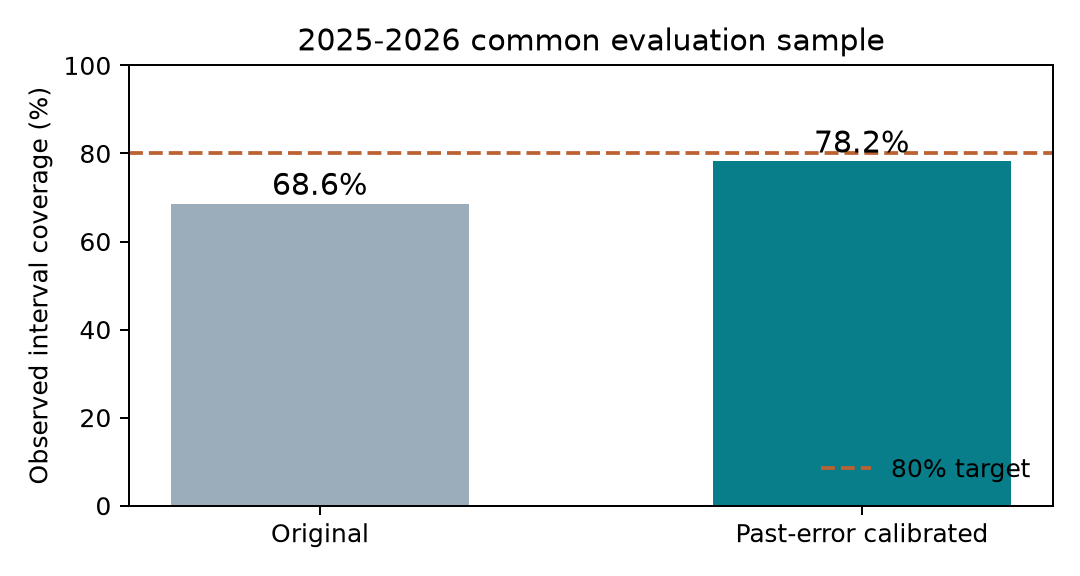

In [3]:
display(Image(filename='reports/calibration_comparison.png'))

## Quantitative findings and commercial interpretation
Boosting coverage rises from 68.6% to 78.2%, with width 76.26 to 92.89 EUR/MWh over 16,488 common 2025+ hours. Negative-price Brier worsens after isotonic calibration; benefits are not uniform.

## Limitations
2024 initializes calibration; earlier test months become past history in later folds. No original source vintage proof or distribution-free time-series coverage guarantee. Fundamental-enhanced pre-clearing comparison is blocked; actual fundamentals never enter these forecasts.

Calculations call reusable modules; regenerate underlying outputs using the README workflow.